# Example of saliency map for local expression

<>:93: SyntaxWarning: invalid escape sequence '\|'
<>:93: SyntaxWarning: invalid escape sequence '\|'
C:\Users\simon\AppData\Local\Temp\ipykernel_13220\2741637076.py:93: SyntaxWarning: invalid escape sequence '\|'
  cbar.set_label("Saliency Magnitude $\|\nabla_{x_i} y_c\|_2$", fontsize=11)
c:\Users\simon\Documents\GitHub\horizon-scanner\.venv\Lib\site-packages\torch\cuda\__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]
C:\Users\simon\AppData\Local\Temp\ipykernel_13220\2741637076.py:72: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('plasma')  # Dark purple (low) -> Yellow (high)


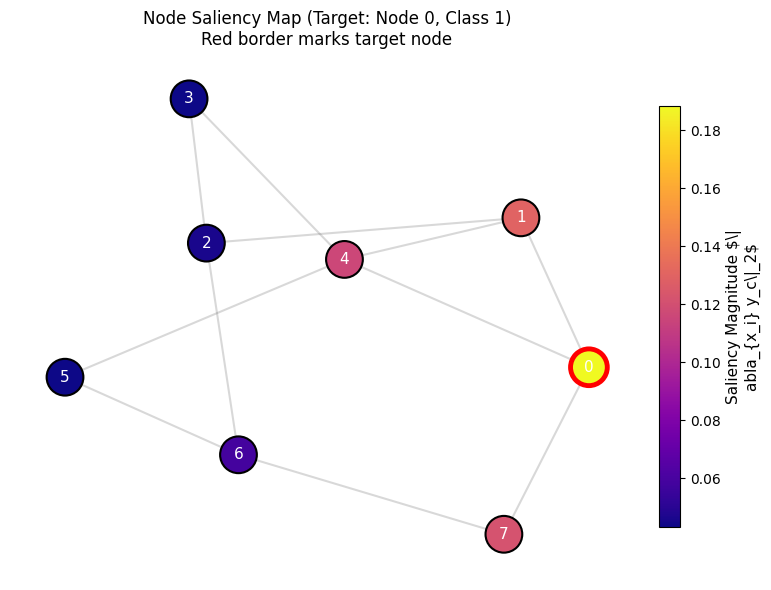

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv
from torch_geometric.data import Data
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors

# 1. Define a standard Graph Neural Network
class GCN(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels):
        super().__init__()
        self.conv1 = GCNConv(in_channels, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, out_channels)

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = self.conv2(x, edge_index)
        return x

# 2. Construct a sample graph (e.g., 8 nodes, 4 features per node)
torch.manual_seed(42)
num_nodes = 8
in_features = 4
num_classes = 2

# Ring graph with cross edges
edges = [
    [0, 1, 2, 3, 4, 5, 6, 7, 0, 2, 4],
    [1, 2, 3, 4, 5, 6, 7, 0, 4, 6, 1]
]
edge_index = torch.tensor(edges, dtype=torch.long)
# Make undirected
edge_index = torch.cat([edge_index, edge_index.flip(0)], dim=1)

x = torch.randn((num_nodes, in_features), dtype=torch.float)
model = GCN(in_channels=in_features, hidden_channels=8, out_channels=num_classes)
model.eval()

# 3. Compute Node Saliency via Gradients
# Enable gradient tracking on node feature tensor
x.requires_grad_(True)

out = model(x, edge_index)

# Select target: e.g., explain the prediction for Node 0
target_node = 0
pred_class = out[target_node].argmax().item()
target_score = out[target_node, pred_class]

# Backpropagate target class logit to input features
target_score.backward()

# S_i = L2-norm of gradients across feature channels for each node
node_gradients = x.grad  # Shape: (N, in_features)
saliency_scores = torch.norm(node_gradients, p=2, dim=1).detach().numpy()

# Min-Max normalize for visualization contrast
saliency_norm = (saliency_scores - saliency_scores.min()) / (
    saliency_scores.max() - saliency_scores.min() + 1e-8
)

# 4. Visualizing with Colored Saliency
G = nx.Graph()
G.add_nodes_from(range(num_nodes))
G.add_edges_from(edge_index.t().numpy().tolist())

pos = nx.spring_layout(G, seed=42)
cmap = cm.get_cmap('plasma')  # Dark purple (low) -> Yellow (high)
node_colors = [cmap(score) for score in saliency_norm]

fig, ax = plt.subplots(figsize=(8, 6))

# Draw graph elements
nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.3, edge_color="gray", width=1.5)
nx.draw_networkx_nodes(
    G, pos, ax=ax,
    node_color=node_colors,
    node_size=700,
    edgecolors=["black" if n != target_node else "red" for n in G.nodes()],
    linewidths=[1.5 if n != target_node else 3.5 for n in G.nodes()]
)
nx.draw_networkx_labels(G, pos, ax=ax, font_size=11, font_color="white")

# Add colorbar for saliency attribution
norm = mcolors.Normalize(vmin=saliency_scores.min(), vmax=saliency_scores.max())
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, shrink=0.8, pad=0.02)
cbar.set_label("Saliency Magnitude $\|\nabla_{x_i} y_c\|_2$", fontsize=11)

ax.set_title(
    f"Node Saliency Map (Target: Node {target_node}, Class {pred_class})\nRed border marks target node",
    fontsize=12
)
ax.axis("off")
plt.tight_layout()
plt.show()